# Лекція 5. Локальний деплоймент і оптимізація моделей

Демо до лекції. Усі моделі в цьому ноутбуці запускаються **локально** через [Ollama](https://ollama.com), їх використання відбувається через HTTP-запити.

## 0. Налаштування середовища

### 0.0. Імпортуємо бібліотеки

In [ ]:
import json
import subprocess
import sys
import time
import urllib.request

OLLAMA_URL = "http://localhost:11434"

### 0.1. Встановлюємо й запускаємо Ollama

Локально цю клітинку можна просто виконати: вона нічого не зробить.

In [ ]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

if IN_COLAB:
    !sudo apt-get -qq install -y zstd > /dev/null
    !curl -fsSL https://ollama.com/install.sh | sh
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    time.sleep(5)

Running in Colab: True
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


### 0.2. Перевіряємо, що Ollama працює

Ollama — це HTTP-сервер на порту 11434. Функція `ollama()` надсилає йому запит і повертає відповідь як словник Python; якщо сервер працює, побачимо його версію.

In [ ]:
def ollama(path, body=None, timeout=900):
    """POST-запит до Ollama (або GET, якщо body=None); повертає розібраний JSON."""
    data = json.dumps(body).encode() if body is not None else None
    req = urllib.request.Request(OLLAMA_URL + path, data=data, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        return json.load(resp)


print("Ollama version:", ollama("/api/version")["version"])

Ollama version: 0.40.15


## 1. Base, Instruct і Thinking

Порівнюємо три поведінки однієї й тієї самої моделі Qwen3 1.7B:
- **Base-модель** пройшла лише попереднє тренування: вона вміє передбачати наступний токен в інтернет-текстах, але не вміє відповідати на питання як асистент.
- **Instruct-модель** додатково донавчили на прикладах «інструкція → відповідь» у форматі діалогу.
- **Thinking** — режим, у якому Instruct-модель перед відповіддю генерує ланцюжок міркувань.

### 1.0. Завантажуємо моделі

Беремо одну й ту саму модель Qwen3 1.7B у двох версіях:
- **Base** — [Qwen3-1.7B-Base](https://huggingface.co/Qwen/Qwen3-1.7B-Base) у форматі GGUF (Q4_K_M) з Hugging Face;
- **Instruct** — офіційна [qwen3:1.7b](https://ollama.com/library/qwen3) з каталогу Ollama; вона ж уміє працювати в режимі міркування.

Перше завантаження займає кілька хвилин.

In [ ]:
BASE_MODEL = "hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M"
INSTRUCT_MODEL = "qwen3:1.7b"

for m in (BASE_MODEL, INSTRUCT_MODEL):
    print("pull", m, "→", ollama("/api/pull", {"model": m, "stream": False})["status"])

pull hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M → success
pull qwen3:1.7b → success


### 1.1. Допоміжні функції

Нам вистачить двох ендпойнтів Ollama:
- `/api/generate` з `"raw": true` — передає моделі текст як є, **без chat template**;
- `/api/chat` — приймає список повідомлень і сам загортає їх у chat template моделі.

У Qwen3 режим міркування вмикається параметром `think`. З `think=True` модель спершу генерує ланцюжок міркувань (Ollama повертає його окремим полем `message.thinking`), а вже потім — відповідь. Функція `compare_thinking()` запускає запит в обох режимах і показує відповідь, кількість згенерованих токенів і час.

In [ ]:
def generate_raw(model, prompt, max_tokens=120):
    """Продовження тексту без chat template — так «бачить» запит Base-модель."""
    r = ollama("/api/generate", {
        "model": model, "prompt": prompt, "raw": True, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })
    return r["response"]


def chat(model, prompt, think=False, max_tokens=3000):
    """Один запит у форматі діалогу; think=True вмикає режим міркування."""
    return ollama("/api/chat", {
        "model": model, "messages": [{"role": "user", "content": prompt}],
        "think": think, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })


def compare_thinking(prompt):
    for think in (False, True):
        r = chat(INSTRUCT_MODEL, prompt, think=think)
        msg = r["message"]
        print(f"=== think={think} | токенів: {r['eval_count']} | генерація: {r['eval_duration'] / 1e9:.1f} с")
        if msg.get("thinking"):
            print(f"--- міркування ({len(msg['thinking'])} символів), початок:")
            print(msg["thinking"][:600], "…")
        print("--- відповідь:")
        print(msg["content"])
        print()

### 1.2. Base: модель просто продовжує текст

Поставимо Base- та Instruct-моделі однакове питання.

In [ ]:
QUESTION = "Яка столиця Франції?"

In [ ]:
print(generate_raw(BASE_MODEL, QUESTION))

 Як називається найбільша річка Франції? Як називається найбільша річка Франції, яка розташована в Північній Америці? Як називається найбільша річка Франції, яка розташована в Півдні Франції? Як називається найбільша р


Для Base-моделі «Яка столиця Франції?» схоже на початок списку питань вікторини — тож вона продовжує цей список, а не відповідає.

### 1.3. Instruct: модель відповідає на питання

In [ ]:
print(chat(INSTRUCT_MODEL, QUESTION)["message"]["content"])

Столиця Франції — це **Париж**.


### 1.4. Instruct проти Thinking: багатокрокова задача

In [ ]:
compare_thinking(
    "У кошику 3 яблука. Марія поклала туди ще 2 пакети по 4 яблука, "
    "а потім зʼїла 2 яблука. Скільки яблук у кошику?"
)

=== think=False | токенів: 252 | генерація: 2.0 с
--- відповідь:
Розглянемо ситуацію крок за кроком:

1. **У кошику 3 яблука.**  
2. **Марія поклала туди ще 2 пакети по 4 яблука.**  
   - Кожен пакет містить 4 яблука, тому:
     $$
     2 \text{ пакети} \times 4 \text{ яблука} = 8 \text{ яблука}
     $$
   - Значить, після додавання пакетів у кошик буде:
     $$
     3 + 8 = 11 \text{ яблука}
     $$
3. **Марія зʼїла 2 яблука.**  
   - Після з’ївання:
     $$
     11 - 2 = 9 \text{ яблука}
     $$

**Відповідь:**  
$$
\boxed{9}
$$

=== think=True | токенів: 569 | генерація: 4.8 с
--- міркування (1410 символів), початок:
Okay, let's see. So the problem is about Maria putting some apples in a basket and then eating some. Let me break it down step by step.

First, the basket starts with 3 apples. Then, Maria adds 2 packages, each containing 4 apples. So, I need to calculate how many apples she adds in total. Each package has 4 apples, and there are 2 packages. So that's 2 times 4, which i

Обидва режими відповідають правильно, але з міркуванням модель генерує в кілька разів більше токенів — а користувач бачить відповідь лише після них. Зверніть увагу: міркує модель англійською, хоча питання українською.

### 1.5. Міркування не гарантують правильності

In [ ]:
compare_thinking("Скільки разів літера «р» трапляється в слові «трансформер»?")

=== think=False | токенів: 227 | генерація: 1.9 с
--- відповідь:
Щоб визначити, скільки разів літера **«р»** трапляється в слові **«трансформер»**, зробимо так:

Слово: **трансформер**

Розбілем його на складні слова:

- **транс**  
- **формер**

Тепер зіштовхуємо літеру **«р»** в кожному з складних слів:

1. **транс** — не має літери «р»  
2. **формер** — має **1** відтінок «р» (відтінок «р» у слові **формер**)

Отже, літера **«р»** трапляється **1 раз** в слові **«трансформер»**.

**Відповідь: 1 раз.**

=== think=True | токенів: 659 | генерація: 5.5 с
--- міркування (1490 символів), початок:
Okay, let's see. The user is asking how many times the letter "р" appears in the word "трансформер". First, I need to make sure I know the correct spelling of the word. The word in question is "трансформер". Let me write it out: трансформер.

Now, I need to check each letter one by one. Let's start from the beginning. The first letter is "т" which is "t" in Ukrainian, but the question is about th

Правильна відповідь — 3 (т**р**ансфо**р**ме**р**), але мала модель помиляється в обох режимах. Чому так — подумайте самі (це питання до лабораторної роботи).

Спробуйте власні запити: де режим міркування справді допомагає, а де лише витрачає токени?

## 2. Квантизація з Quanto

Завантажимо ту саму модель у чотирьох варіантах — від оригінальних 16 біт до 2 біт — і подивимося, що квантизація змінює в памʼяті, швидкості та якості. Якість перевіримо трьома способами: перплексією, перекладом з автоматичними метриками й очима — на вільній генерації тексту.

**Quanto.** [Optimum Quanto](https://github.com/huggingface/optimum-quanto) — бібліотека квантизації від Hugging Face, один із бекендів [Optimum](https://huggingface.co/docs/optimum). У Transformers вона підключається через [`QuantoConfig`](https://huggingface.co/docs/transformers/quantization/quanto) і квантизує модель прямо під час завантаження, тому окремий файл з квантизованими вагами не потрібен. Квантизуються ваги лінійних шарів (`nn.Linear`) — у них більшість параметрів моделі, а ембединги, нормалізації та вихідний шар лишаються в 16 бітах.

| Варіант | Біт на вагу | Що це |
|---|---|---|
| fp16 | 16 | Оригінальні ваги, точка відліку |
| int8 | 8 | 8-бітні цілі числа з масштабом |
| int4 | 4 | 4-бітні цілі числа, ваги діляться на блоки з власними масштабами |
| int2 | 2 | 2-бітні цілі числа — лише 4 можливі значення на вагу; тут модель має зламатися |

**Обчислення.** Множити числа в цих форматах напряму T4 не вміє, тому перед множенням ваги розпаковуються в 16 біт. Тому памʼяті потрібно менше, а от генерація часто **не прискорюється**, а то й сповільнюється.

**Де запускати.** Секцію запускаємо **в Google Colab на GPU T4** (Runtime → Change runtime type → T4 GPU). Беремо формат **fp16**, а не bf16: T4 не підтримує bf16 апаратно, а для запуску готової моделі різниця між ними практично непомітна.

In [ ]:
# Вивантажуємо моделі Ollama з відеопамʼяті перед секцією 2
for m in (BASE_MODEL, INSTRUCT_MODEL):
    ollama("/api/generate", {"model": m, "keep_alive": 0})
print("Моделі вивантажено")

Моделі вивантажено


### 2.0. Встановлюємо бібліотеки й перевіряємо GPU

In [ ]:
%pip uninstall -y -q diffusers  # optimum-quanto імпортує diffusers, якщо він є; передвстановлена в Colab версія несумісна з його torchao
%pip install -q "transformers==5.20.1" "accelerate==1.15.0" "optimum-quanto==0.2.7" "evaluate==0.4.6" "sacrebleu==2.6.0"

In [ ]:
import gc
import time
from types import SimpleNamespace

import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from optimum.quanto.library.extensions import get_extension
from transformers import AutoModelForCausalLM, AutoTokenizer, QuantoConfig

assert torch.cuda.is_available(), "Увімкніть GPU: Runtime → Change runtime type → T4 GPU"
DEVICE = "cuda"
DTYPE = torch.float16
print("GPU:", torch.cuda.get_device_name())


def unpack_weights(packed, bits):
    """Розпаковує 4- чи 2-бітні значення, по кілька упакованих в одному байті."""
    values_per_byte = 8 // bits
    mask = 2**bits - 1
    return torch.cat([(packed >> (bits * i)) & mask for i in range(values_per_byte)]).to(torch.uint8)


# Quanto на GPU компілює власні CUDA-ядра, розраховані на A100 і новіші; на T4 ця компіляція падає.
# На T4 з усіх цих ядер потрібна лише розпаковка int4/int2-ваг, тож підставляємо її версію на чистому PyTorch.
if torch.cuda.get_device_capability()[0] < 8:
    get_extension("quanto_cuda")._lib = SimpleNamespace(unpack=unpack_weights)

GPU: Tesla T4


### 2.1. Модель і варіанти квантизації

Беремо [Qwen3-4B-Instruct-2507](https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507) — сильнішу модель того ж сімейства, що й у секції 1: 4B параметрів, лише Instruct-режим без міркувань. У fp16 вона займає ~8 GB і вміщається в T4 з його 16 GB.

In [ ]:
MODEL_ID = "Qwen/Qwen3-4B-Instruct-2507"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

VARIANTS = {
    "fp16": None,
    "int8": QuantoConfig(weights="int8"),
    "int4": QuantoConfig(weights="int4"),
    "int2": QuantoConfig(weights="int2"),
}

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.38k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

### 2.2. Що міряємо

**Перплексія** — стандартна автоматична метрика якості квантизації (нею міряє, зокрема, llama.cpp). Модель читає фіксований текст, і для кожного токена ми дивимося, яку ймовірність вона йому давала. Перплексія — це, грубо кажучи, з якої кількості варіантів модель у середньому «вагалася»: чим вона менша, тим краще модель знає мову й тему. Еталонних відповідей тут не потрібно, а число змінюється плавно, тому видно навіть невеликі втрати. Порівнювати перплексію можна лише в межах однієї мови: англійська й українська токенізуються по-різному.

**Переклад EN → UK** — реалістичне завдання з генерацією тексту, для якого є еталонні переклади. Порівнюємо переклад моделі з еталоном двома стандартними метриками з бібліотеки [Evaluate](https://huggingface.co/docs/evaluate):
- [**chrF**](https://github.com/huggingface/evaluate/blob/main/metrics/chrf/README.md) — наскільки збігаються послідовності символів (0–100);
- [**BLEU**](https://github.com/huggingface/evaluate/tree/main/metrics/sacrebleu) — наскільки збігаються послідовності слів (0–100). Сувора метрика: синонім чи інший порядок слів уже знижують бал.

**Вільна генерація** — лист, пояснення, план, код. Тут еталону немає, тож оцінюємо очима в 2.5.

Крім якості, для кожного варіанта записуємо **памʼять моделі** на GPU, **пік VRAM** і **швидкість генерації** (tokens/s).

In [ ]:
PPL_TEXT = {
    "English": (
        "Photosynthesis is the process by which green plants, algae and some bacteria turn light energy into "
        "chemical energy. It takes place mainly in the leaves, inside small structures called chloroplasts, which "
        "contain the green pigment chlorophyll. Chlorophyll absorbs sunlight, and the plant uses this energy to "
        "combine carbon dioxide from the air with water from the soil. The result is glucose, a sugar that the "
        "plant uses for growth and as a store of energy, and oxygen, which is released into the atmosphere. "
        "Almost all life on Earth depends on photosynthesis: it produces the oxygen we breathe and forms the "
        "basis of most food chains."
    ),
    "Українська": (
        "Фотосинтез — це процес, під час якого зелені рослини, водорості та деякі бактерії перетворюють енергію "
        "світла на хімічну енергію. Він відбувається переважно в листках, усередині маленьких структур, які "
        "називають хлоропластами і які містять зелений пігмент хлорофіл. Хлорофіл поглинає сонячне світло, і "
        "рослина використовує цю енергію, щоб поєднати вуглекислий газ із повітря з водою із ґрунту. У результаті "
        "утворюються глюкоза — цукор, який рослина використовує для росту і як запас енергії, — та кисень, що "
        "виділяється в атмосферу. Майже все життя на Землі залежить від фотосинтезу: він дає кисень, яким ми "
        "дихаємо, і лежить в основі більшості харчових ланцюгів."
    ),
}

TRANSLATION = [
    # (речення англійською, еталонний переклад)
    ("The meeting has been moved to Thursday at three o'clock.", "Зустріч перенесли на четвер на третю годину."),
    ("Please send me the report by the end of the day.", "Будь ласка, надішліть мені звіт до кінця дня."),
    ("The library is closed on Sundays and public holidays.", "Бібліотека не працює в неділю та у святкові дні."),
    ("Our team fixed the bug, but the tests are still failing.", "Наша команда виправила помилку, але тести все ще не проходять."),
    ("It is going to rain tomorrow, so take an umbrella.", "Завтра буде дощ, тож візьміть парасольку."),
    ("The new model is smaller, but it answers almost as well as the old one.", "Нова модель менша, але відповідає майже так само добре, як стара."),
    ("I would like to book a table for two for seven o'clock tonight.", "Я хотів би забронювати столик на двох на сьому вечора."),
    ("The price includes breakfast and free Wi-Fi.", "У вартість входять сніданок і безкоштовний Wi-Fi."),
    ("Students must submit their lab work before the deadline.", "Студенти мають здати лабораторну роботу до кінцевого терміну."),
    ("If the server does not respond, restart it and check the logs.", "Якщо сервер не відповідає, перезапустіть його й перевірте логи."),
]
TRANSLATE_PROMPT = "Translate the following sentence into Ukrainian. Output only the translation.\n\n{}"

GEN_PROMPTS = [
    "Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.",
    "Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.",
    "Explain in three sentences why the sky is blue.",
    "Склади план підготовки до іспиту з програмування на 5 днів, по одному пункту на день.",
    "Write a Python function that checks whether a string is a palindrome.",
]

### 2.3. Проганяємо всі варіанти

Дві допоміжні функції — перплексія тексту й генерація відповіді — і цикл по варіантах: завантажуємо модель, міряємо все потрібне, звільняємо памʼять. Займає кілька хвилин на варіант.

In [ ]:
def perplexity(model, text):
    """exp(середня похибка передбачення наступного токена) на фіксованому тексті."""
    ids = tokenizer(text, return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        loss = model(ids, labels=ids).loss
    return float(torch.exp(loss))


def generate(model, prompt, max_new_tokens):
    """Відповідь без випадковості; повертає текст, кількість нових токенів і час генерації."""
    text = tokenizer.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(DEVICE)
    torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    new_tokens = output[0, inputs.input_ids.shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip(), len(new_tokens), time.perf_counter() - start


records = {}
for name, config in VARIANTS.items():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE, quantization_config=config)

    r = {"памʼять моделі, GB": torch.cuda.memory_allocated() / 1e9}
    for lang, text in PPL_TEXT.items():
        r[f"перплексія, {lang}"] = perplexity(model, text)
    r["переклади"] = [generate(model, TRANSLATE_PROMPT.format(src), 80)[0] for src, _ in TRANSLATION]
    generations = [generate(model, prompt, 200) for prompt in GEN_PROMPTS]
    r["генерації"] = [text for text, _, _ in generations]
    r["tokens/s"] = sum(n for _, n, _ in generations) / sum(s for _, _, s in generations)
    r["пік VRAM, GB"] = torch.cuda.max_memory_allocated() / 1e9
    records[name] = r
    print(f"{name}: готово")

    del model

model.safetensors.index.json:   0%|          | 0.00/32.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

fp16: готово


... (2 outputs left out)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int4: готово


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int2: готово


### 2.4. Памʼять, швидкість і автоматичні метрики

In [ ]:
chrf = evaluate.load("chrf")
bleu = evaluate.load("sacrebleu")
references = [[ref] for _, ref in TRANSLATION]

summary = pd.DataFrame({
    name: {
        "памʼять моделі, GB": r["памʼять моделі, GB"],
        "пік VRAM, GB": r["пік VRAM, GB"],
        "tokens/s": r["tokens/s"],
        **{f"перплексія, {lang}": r[f"перплексія, {lang}"] for lang in PPL_TEXT},
        "chrF перекладу": chrf.compute(predictions=r["переклади"], references=references)["score"],
        "BLEU перекладу": bleu.compute(predictions=r["переклади"], references=references)["score"],
    }
    for name, r in records.items()
}).T.round(2)
summary

,"памʼять моделі, GB","пік VRAM, GB",tokens/s,"перплексія, English","перплексія, Українська",chrF перекладу,BLEU перекладу
fp16,8.04,8.64,17.17,2.67,2.40,55.22,23.71
int8,4.42,5.01,5.60,2.67,2.40,58.25,26.17
int4,2.73,3.32,2.85,2.81,2.76,55.34,29.79
int2,1.81,2.39,2.92,60091.86,34451480.00,0.19,0.12


Перплексія для кожної мови окремо. Вісь — логарифмічна: інакше на одному графіку не помістилися б і кілька одиниць, і сотні.

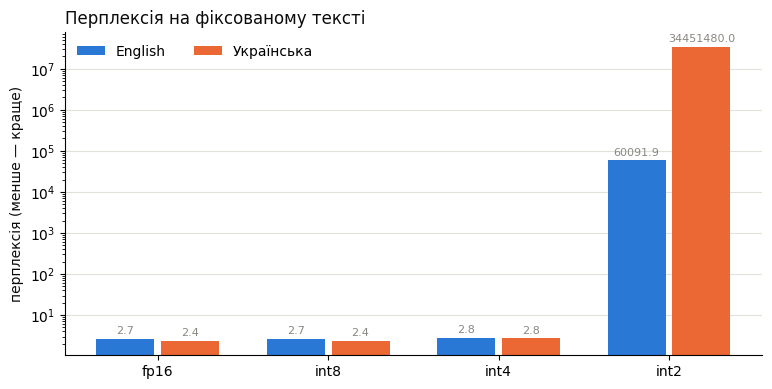

In [ ]:
LANG_COLORS = {"English": "#2a78d6", "Українська": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

variants = list(records)
x = np.arange(len(variants))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, lang in enumerate(PPL_TEXT):
    values = summary[f"перплексія, {lang}"].values
    bars = ax.bar(x + (i - 0.5) * width, values, width - 0.04, color=LANG_COLORS[lang], label=lang)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], fontsize=8, color=MUTED, padding=2)
ax.set_yscale("log")
ax.set_xticks(x, variants)
ax.set_ylabel("перплексія (менше — краще)", color=INK)
ax.set_title("Перплексія на фіксованому тексті", loc="left", color=INK)
ax.legend(frameon=False, ncols=2, loc="upper left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

Переклади всіх варіантів поруч з еталоном:

In [ ]:
translations = pd.DataFrame({"еталон": [ref for _, ref in TRANSLATION]}, index=[src for src, _ in TRANSLATION])
for name, r in records.items():
    translations[name] = r["переклади"]
translations

,еталон,fp16,int8,int4,int2
The meeting has been moved to Thursday at three o'clock.,Зустріч перенесли на четвер на третю годину.,"Зустріч була перенесена на четвер, о 15 годин.","Зустріч перенесли на четвер, о 15 годин.","Зустріч була перенесена на четвер, о 15 годин.",`` takenosthawkhhhawkoft0houghth``t`\'uleh'thh...
Please send me the report by the end of the day.,"Будь ласка, надішліть мені звіт до кінця дня.",Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,takenawns between't```````````````````h``` \`e...
The library is closed on Sundays and public holidays.,Бібліотека не працює в неділю та у святкові дні.,Бібліотека закривається у неділі та дні відпоч...,Бібліотека закривається у неділі та дні відпоч...,Бібліотека відкрита тільки з 1 по 7.,`ever �house �take caught}}house0}0 taken take...
"Our team fixed the bug, but the tests are still failing.","Наша команда виправила помилку, але тести все ...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тести все ще н...",fil}'sand ever0'f}'h \n'}'}''}'' \n' \n \n ...
"It is going to rain tomorrow, so take an umbrella.","Завтра буде дощ, тож візьміть парасольку.","Завтра піде дощ, тому взміть засіб.","Завтра піде дощ, тому взміть з собою парасольку.","Завтра буде дощ, тому взміть засіб.",}again \蚊} taken \neverh. \n \nagain \n \n...
"The new model is smaller, but it answers almost as well as the old one.","Нова модель менша, але відповідає майже так са...","Новий модель менший, але відповідає почти так ...","Новий модель менший, але відповідає приблизно ...","Новий модель менший, але відповідає почти так ...",fil��''}\n0. between'h ’h ` between betweenfec...
I would like to book a table for two for seven o'clock tonight.,Я хотів би забронювати столик на двох на сьому...,Я бажаю забронювати стіл для двох на сім годин...,Я бажаю забронювати стіл для двох на сім годин...,Я б хотів зареєструвати стіл для двох на 7 год...,``ever``always```comeight`[\n`letic touched`ev...
The price includes breakfast and free Wi-Fi.,У вартість входять сніданок і безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та вільний Wi-Fi.,.前所eterminefilosterone0 00 \00 \tt011011OFF00e...
Students must submit their lab work before the deadline.,Студенти мають здати лабораторну роботу до кін...,Студенти повинні подати свою лабораторну робот...,Студенти повинні подати свою лабораторну робот...,Студенти повинні відправляти лабораторну робот...,he $everearned a0001100evers \n0\n\nhehe0'tou...
"If the server does not respond, restart it and check the logs.","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...",ever. taken againoughtbetweenhtonhhofthhbetwee...


### 2.5. Сліпе порівняння: fp16 проти int4

Автоматичні метрики показали, наскільки int4 відрізняється від fp16 у числах. Тепер перевірмо очима — так, як це роблять оцінювачі-люди: для кожного запиту показуємо дві відповіді, fp16 та int4, **у випадковому порядку й без підписів**. Ваше завдання — обрати кращу.

In [ ]:
rng = np.random.default_rng(0)
BLIND_ORDER = [rng.permutation(["fp16", "int4"]) for _ in GEN_PROMPTS]

for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for label, name in zip("AB", BLIND_ORDER[i]):
        display(Markdown(f"**Відповідь {label}:**\n\n{records[name]['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**Відповідь A:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**Відповідь B:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

**Відповідь A:**

Квантизація нейромережі — це процес зменшення точності ваг між нейронами в мережі, щоб зменшити об’єм пам’яті та швидкість обчислень. Вона полягає у заміні дробових чисел (наприклад, з плаваючою комою) на цілі числа (наприклад, з кількома бітами). Це дозволяє запускати мережі на пристроях з обмеженою відповідністю, таких як мобільні телефони або IoT-апарати. Насправді, квантизація не втрачає повно

**Відповідь B:**

Квантизація нейромережі — це процес зменшення точності ваг (зв'язків між нейронами) до тих рівнів, що можна зберігати в комп'ютері з меншою відповідністю до об’ємних ресурсів. Це робиться для зменшення об’єму пам’яті та швидкості обчислень. Наприклад, ваги можуть бути зображено як цілі числа (наприклад, 8 біт) замість дробових чисел. Це зручно для використання на пристроях з обмеженими ресурс

... (5 outputs left out)

**Відповідь B:**

Ось чіткий і практичний план підготовки до іспиту з програмування на 5 днів — по одному ключовому темі на день. Цей план призначений для студентів, які вивчають програмування на початковому або середньому рівні (наприклад, на мові Python, Java або C++), але може бути адаптований під будь-яку мову.

---

**День 1: Основні структури даних та їх використання**

- Повторити: змінні, типи даних, оператори, вирази.
- Вивчити: списки, кортежі, слов

---
#### Запит 5: Write a Python function that checks whether a string is a palindrome.

**Відповідь A:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**Відповідь B:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

Для кожного запиту запишіть **"A"** або **"B"** — яка відповідь краща, або **"="**, якщо однакові за якістю. Потім запустіть наступну клітинку, щоб дізнатися, де була яка модель.

In [ ]:
VOTES = {1: "A", 2: "B", 3: "=", 4: "A", 5: "B"}

In [ ]:
if all(v in ("A", "B", "=") for v in VOTES.values()):
    rows = []
    for i, vote in VOTES.items():
        order = dict(zip("AB", BLIND_ORDER[i - 1]))
        rows.append({"запит": GEN_PROMPTS[i - 1], "A": order["A"], "B": order["B"],
                     "ваш вибір": "однаково" if vote == "=" else order[vote]})
    display(pd.DataFrame(rows))
    choices = [r["ваш вибір"] for r in rows]
    print(f"fp16 краща: {choices.count('fp16')}, int4 краща: {choices.count('int4')}, однаково: {choices.count('однаково')}")
else:
    print('Заповніть VOTES значеннями "A", "B" або "=" для всіх 5 запитів.')

,запит,A,B,ваш вибір
0,Напиши короткий лист викладачеві з проханням п...,fp16,int4,fp16
1,Поясни студентові першого курсу в 3–4 реченнях...,fp16,int4,int4
2,Explain in three sentences why the sky is blue.,fp16,int4,однаково
3,Склади план підготовки до іспиту з програмуван...,int4,fp16,int4
4,Write a Python function that checks whether a ...,int4,fp16,fp16


fp16 краща: 2, int4 краща: 2, однаково: 1


### 2.6. Відповіді всіх варіантів

Тепер, коли сліпе порівняння зроблено, — відповіді всіх варіантів з підписами, включно з int8 та int2. Еталону тут немає, тож читаємо самі.

In [ ]:
for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for name, r in records.items():
        display(Markdown(f"**{name}:**\n\n{r['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**fp16:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**int8:**

Ось приклад короткого листа викладачеві:

---

**Дорогий [Ім’я викладача]!**

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу.  
Буду дуже вдячний за розуміння та гнучкість.

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Контактна інформація, якщо потрібно]

---

Цей лист короткий, виразний та відповідає формату прохання. Можна адаптувати під конкретну ситуацію.

**int4:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

**int2:**

°°h\ter°\n h hsd°°ampton \ \
 \
:
h h h h : had had had had had had again had had had had h bettb h hhtonhtonsd**leehtonhtonsdhtonhtonhtonhtonhtonhtonhton (%) nuts9 system \ \ rest  \} \} \n \ \ \ \  \ \ \ \ h \ \ \ h \ \ h \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \  \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ the \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

... (15 outputs left out)

**fp16:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int8:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int4:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**int2:**

\
 \'  
\' 
\' \ \ \ \ \\'\' \ \ \ \ \\' \\' \ OFF ** \ - [\'0 \'\'\'\'\'\' \' \ \ \ 
 
  \ 
5  \ \ \\ \ 
 
0 \ -  - - - - - - - - - - -  \ \ - - - - \  
\' \ \\'\' \\'\'    - - sent\'\'\'\'\n\'\' \ \ \ \ \ \ \ \ \ \ \ \ \ \ - - \ -  - -  -\'20\' \' - - - - - - - - - \ \' - -':
 - - - - - - - - - -   - - - - - - - - - - - - - - - - - - - - - -LOCK  \ -  \ -\' \ \ \   PRO \ - - - - - -

## 3. Відповіді на питання 0.1

In [ ]:
# Зберігаємо результати моделі 4B: питання 17 повторить секцію 2 для меншої моделі й перезапише records та summary
records_4b, summary_4b = records, summary
print("Збережено:", list(records_4b))

Збережено: ['fp16', 'int8', 'int4', 'int2']


### Питання 1. Чому модель помиляється, рахуючи літеру «р» у слові «трансформер»?

Модель не бачить літер: перед обробкою текст розбивається токенізатором на підслова, і модель працює з номерами токенів. Слово «трансформер» (11 літер) розбилося на 5 токенів: «т», «ран», «с», «форм», «ер» (id 1792, 34582, 2247, 56619, 7599). Щоб порахувати «р», модель має «знати», які літери входять до кожного токена, але такої інформації в неї немає явно: вона є лише побічно, зі статистики текстів. До того ж три літери «р» заховані всередині трьох різних токенів («ран», «форм», «ер»), тож їх легко пропустити або порахувати двічі.

У режимі міркування модель намагається розписати слово по літерах, але робить це тими самими токенами й тією самою памʼяттю, тож помилка лишається. У виводі 1.5 вона навіть розписала слово неправильно («т, р, а, н, с, т, о, м, е, р»: без «ф» і з зайвою «т») і відповіла 2. Без міркування відповідь була 1. Код вище підтверджує: літери «р» розкидані по токенах, а жоден токен не є окремою літерою.

In [ ]:
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained("Qwen/Qwen3-1.7B")
word = "трансформер"
ids = tok(word, add_special_tokens=False).input_ids
pieces = [tok.decode([i]) for i in ids]
print(f"{len(word)} літер → {len(ids)} токенів: {pieces}")
print("id токенів:", ids)
print("Справжня кількість «р»:", word.count("р"))
for p in pieces:
    print(repr(p), "→ літер «р» у токені:", p.count("р"))

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

11 літер → 5 токенів: ['т', 'ран', 'с', 'форм', 'ер']
id токенів: [1792, 34582, 2247, 56619, 7599]
Справжня кількість «р»: 3
'т' → літер «р» у токені: 0
'ран' → літер «р» у токені: 1
'с' → літер «р» у токені: 0
'форм' → літер «р» у токені: 1
'ер' → літер «р» у токені: 1


### Питання 2. Як змінюються перплексія й метрики перекладу від fp16 до int2? Між якими варіантами стрибок найбільший?

Результати для 4B (таблиця 2.4):

| Варіант | Перплексія EN | Перплексія UA | chrF | BLEU |
|---|---|---|---|---|
| fp16 | 2.67 | 2.40 | 55.22 | 23.71 |
| int8 | 2.67 | 2.40 | 58.25 | 26.17 |
| int4 | 2.81 | 2.76 | 55.34 | 29.79 |
| int2 | 60 092 | 34 451 480 | 0.19 | 0.12 |

Від fp16 до int8 перплексія не змінюється. Від int8 до int4 вона зростає трохи (EN +5%, UA +15%). Від int4 до int2 вона обвалюється в тисячі й мільйони разів, а chrF і BLEU падають майже до нуля: це **найбільший стрибок**, модель перестає виконувати завдання. Метрики перекладу в fp16, int8 та int4 лишаються в одному діапазоні: невеликі відмінності (навіть «кращі» chrF/BLEU в int8 та int4) на 10 реченнях є шумом, а не покращенням.

### Питання 3. Чи однаково зростає перплексія для англійської й української?

Ні, не однаково. Відносно fp16 в int4 перплексія англійської зросла в 1.05 раза (2.67 → 2.81), української в 1.15 раза (2.40 → 2.76), тобто українська втрачає втричі більше. В int2 колапс у обох мов, але в української він набагато сильніший (у 14 354 783 раза проти 22 506 в англійської). Порівнювати абсолютні значення між мовами не можна, тому дивимося лише на зміну відносно fp16 (таблиця вище).

Це узгоджується з очікуванням, що менш представлена в тренувальних даних мова (українська) від втрати точності ваг страждає сильніше за англійську.

In [ ]:
cols = ["перплексія, English", "перплексія, Українська"]
rel = (summary_4b[cols] / summary_4b.loc["fp16", cols]).round(2)
rel.columns = ["English, × від fp16", "Українська, × від fp16"]
rel

,"English, × від fp16","Українська, × від fp16"
fp16,1.00,1.00
int8,1.00,1.00
int4,1.05,1.15
int2,22506.31,14354783.33


### Питання 4. Чи збігається ваш вибір у сліпому порівнянні з автоматичними метриками?

**Автоматичні метрики:** fp16 та int4 майже не відрізняються (перплексія +5% EN і +15% UA, chrF 55.2 проти 55.3), тож очікується, що в сліпому порівнянні різниця буде малопомітною.

Так, мій вибір збігається з автоматичними метриками. У сліпому порівнянні я обрав fp16 у 2 запитах (лист, код), int4 у 2 (пояснення, план) і в 1 запиті (небо) визнав відповіді однаковими, тобто стійкої переваги жодного варіанта не було. Метрики показали те саме: перплексія int4 зросла лише на 5% (EN) і 15% (UA), а chrF майже не змінився (55.2 проти 55.3). Там, де метрики майже не змінилися, я теж не відчув різниці: у двох запитах українською (пояснення й план) мені навіть більше сподобалась int4, тож вона була не гіршою за fp16.

### Питання 5. Правильний переклад, що відрізняється від еталона словами: як реагують BLEU і chrF?

Правильні переклади, що відрізняються від еталона словами (клітинка вище, оцінки для одного речення):

- «The library is closed on Sundays and public holidays.» Модель (fp16): «Бібліотека закривається у неділі та дні відпочинку». Еталон: «Бібліотека не працює в неділю та у святкові дні». Сенс правильний, але слова інші: **chrF 36.7, BLEU 6.4**.
- «Please send me the report by the end of the day.» Модель: «Надішліть мені звіт до кінця дня» (без «Будь ласка»). **chrF 73.1, BLEU 52.7**.

BLEU рахує збіги цілих слів і послідовностей слів (до 4-грам), тому синоніми й інший порядок слів дають майже нуль збігів, і оцінка різко падає (6.4). chrF рахує збіги символьних n-грам, тож спільні корені й закінчення (бібліотек-, неділ-, та) дають часткову оцінку, і вона вища (36.7). Обидві метрики штрафують правильний, але інакше сформульований переклад, а chrF м'якше. Тому на 10 реченнях з одним еталоном ці метрики грубі й порівнювати варіанти варто обережно.

In [ ]:
# Переклади, які не збігаються з еталоном дослівно, з оцінками chrF і BLEU для окремого речення
for name in ("fp16", "int8", "int4"):
    for (src, ref), hyp in zip(TRANSLATION, records_4b[name]["переклади"]):
        if hyp.strip() != ref:
            c = chrf.compute(predictions=[hyp], references=[[ref]])["score"]
            b = bleu.compute(predictions=[hyp], references=[[ref]])["score"]
            print(f"{name} | {src}\n    модель: {hyp}\n    еталон: {ref}\n    chrF {c:.1f} | BLEU {b:.1f}\n")

fp16 | The meeting has been moved to Thursday at three o'clock.
    модель: Зустріч була перенесена на четвер, о 15 годин.
    еталон: Зустріч перенесли на четвер на третю годину.
    chrF 49.9 | BLEU 10.0

fp16 | Please send me the report by the end of the day.
    модель: Надішліть мені звіт до кінця дня.
    еталон: Будь ласка, надішліть мені звіт до кінця дня.
    chrF 73.1 | BLEU 52.7

fp16 | The library is closed on Sundays and public holidays.
    модель: Бібліотека закривається у неділі та дні відпочинку.
    еталон: Бібліотека не працює в неділю та у святкові дні.
    chrF 36.7 | BLEU 6.4

fp16 | Our team fixed the bug, but the tests are still failing.
    модель: Наша команда виправила баг, але тестування все ще не працюють.
    еталон: Наша команда виправила помилку, але тести все ще не проходять.
    chrF 60.7 | BLEU 24.8

fp16 | It is going to rain tomorrow, so take an umbrella.
    модель: Завтра піде дощ, тому взміть засіб.
    еталон: Завтра буде дощ, тож візьміть парас

### Питання 6. У скільки разів зменшилася памʼять і чому не рівно вдвічі, вчетверо й увосьмеро? Чи стала генерація швидшою?

Памʼять зменшилась у **1.8 раза** (fp16 8.04 → int8 4.42 GB), **2.95 раза** (→ int4 2.73 GB) і **4.4 раза** (→ int2 1.81 GB), а не в 2, 4 і 8. Причина: квантизуються лише ваги лінійних шарів, а ембединги, нормалізації й вихідний шар лишаються в 16 бітах. У Qwen3-4B ембединги (151 936 × 2 560 параметрів, вихідний шар із ними повʼязаний) займають **0.78 GB**, тобто ≈10% від 8.04 GB, і вони не стискаються. Решта (≈7.26 GB) стискається: 0.78 + 7.26/2 ≈ 4.41 GB (int8), 0.78 + 7.26/4 ≈ 2.60 GB (int4), 0.78 + 7.26/8 ≈ 1.69 GB (int2). Ще ≈0.1 GB в int4 та int2 дають масштаби блоків ваг (кожен блок має власний масштаб).

Генерація **не стала швидшою, а стала повільнішою**: fp16 17.2 tok/s, int8 5.6, int4 2.85, int2 2.9. T4 не вміє множити в int8/int4/int2 напряму, тож ваги щоразу розпаковуються в 16 біт (на T4 розпаковка int4/int2 виконується на чистому PyTorch, а не в CUDA-ядрах), і ця додаткова робота перекриває економію на читанні памʼяті. Тут квантизація економить памʼять, але не час.

In [ ]:
mem = summary_4b["памʼять моделі, GB"]
expected = {"fp16": 1, "int8": 2, "int4": 4, "int2": 8}
display(pd.DataFrame({
    "памʼять, GB": mem.round(2),
    "зменшення (факт), ×": (mem.loc["fp16"] / mem).round(2),
    "зменшення (за кількістю біт), ×": pd.Series(expected),
    "tokens/s": summary_4b["tokens/s"],
}))

# Ембединги лишаються в fp16 і не квантизуються: оцінимо їхню частку в памʼяті
from transformers import AutoConfig
for mid in ("Qwen/Qwen3-4B-Instruct-2507", "Qwen/Qwen3-1.7B"):
    cfg = AutoConfig.from_pretrained(mid)
    emb = cfg.vocab_size * cfg.hidden_size * 2 / 1e9
    print(f"{mid}: ембединги {cfg.vocab_size} × {cfg.hidden_size} = {emb:.2f} GB у fp16 (tie_word_embeddings={cfg.tie_word_embeddings})")

,"памʼять, GB","зменшення (факт), ×","зменшення (за кількістю біт), ×",tokens/s
fp16,8.04,1.00,1,17.17
int8,4.42,1.82,2,5.60
int4,2.73,2.95,4,2.85
int2,1.81,4.44,8,2.92


Qwen/Qwen3-4B-Instruct-2507: ембединги 151936 × 2560 = 0.78 GB у fp16 (tie_word_embeddings=True)
Qwen/Qwen3-1.7B: ембединги 151936 × 2048 = 0.62 GB у fp16 (tie_word_embeddings=True)


### Питання 7. Чому Base-модель відповідає на питання новими питаннями? Промпт, після якого вона відповідає

Base-модель пройшла лише попереднє тренування й уміє лише продовжувати текст. Запитання «Яка столиця Франції?» виглядає як початок списку питань вікторини, тож найімовірніше продовження це наступні питання (у виводі 1.2: «Як називається найбільша річка Франції?…»). Chat template та інструкції їй незнайомі.

Щоб отримати відповідь, треба сформулювати промпт так, щоб відповідь була найімовірнішим продовженням: почати речення, яке природно закінчується відповіддю. Результати (клітинка вище):

- «Столицею Франції є місто» → « Париж, яке є одним із най…»
- «Питання: Яка столиця Франції?\nВідповідь: Столицею Франції є місто» → « Париж.»
- з прикладом (few-shot) «…Відповідь: Столицею Італії є Рим.\n\nПитання: Яка столиця Франції?\nВідповідь: Столицею Франції є» → « Париж.»

Коротка форма «Відповідь:» з прикладом «Рим» натомість дала « Паризька», тож повне речення працює надійніше.

In [ ]:
# Base-модель лише продовжує текст, тож формулюємо промпт як початок речення, яке природно завершується відповіддю
candidates = [
    "Столицею Франції є місто",
    "Питання: Яка столиця Франції?\nВідповідь: Столицею Франції є місто",
    "Питання: Яка столиця Італії?\nВідповідь: Столицею Італії є Рим.\n\nПитання: Яка столиця Франції?\nВідповідь: Столицею Франції є",
]
for prompt in candidates:
    r = ollama("/api/generate", {"model": BASE_MODEL, "prompt": prompt, "raw": True, "stream": False,
                                 "options": {"temperature": 0, "seed": 1, "num_predict": 12, "stop": ["\n"]}})
    print(repr(prompt), "→", repr(r["response"]))

'Столицею Франції є місто' → ' Париж, яке є одним із най'
'Питання: Яка столиця Франції?\nВідповідь: Столицею Франції є місто' → ' Париж.'
'Питання: Яка столиця Італії?\nВідповідь: Столицею Італії є Рим.\n\nПитання: Яка столиця Франції?\nВідповідь: Столицею Франції є' → ' Париж.'


### Питання 8. Скільки токенів і часу забрали міркування в розділі 1.4? Чому модель міркує англійською?

У розділі 1.4 (задача про яблука) без міркування модель згенерувала **252 токени за 2.0 с**, з міркуванням **569 токенів за 4.8 с**: у 2.3–2.4 раза більше токенів і часу, до того ж користувач бачить відповідь лише після завершення міркувань. У розділі 1.5 (літера «р»): 227 токенів / 1.9 с проти 659 токенів / 5.5 с.

Модель міркує англійською, бо ланцюжки міркувань, на яких її навчали (особливо на етапі навчання з підкріпленням на задачах), були переважно англомовними. Мова міркування не залежить від мови питання, а фінальну відповідь модель видає мовою питання.

### Питання 9. Задача, на якій режим міркування дає правильну відповідь, а без нього модель помиляється

**Промпт:** «У сімʼї три сестри, і в кожної з них є рівно один брат. Скільки всього дітей у сімʼї?» Правильно: **4** (три сестри й один спільний брат).

- **Без міркування** (think=False, 106 токенів): «3 сестри і 3 брати. Отже, всього у сімʼї 3 + 3 = 6 дітей» — **неправильно**.
- **З міркуванням** (think=True, 1562 токени, 14.1 с): «3 сестри + 1 брат = 4 діти», відповідь 4 — **правильно**.

Без міркування модель схопила шаблон «кожній по брату», а міркування дозволило помітити, що брат один спільний. Це не завжди так: на простих задачах (23 × 47 + 119, біта й мʼяч, 5 машин) модель відповіла правильно й без міркування, а в задачі про 5 машин режим міркування навіть уперся в ліміт 3000 токенів і не дав відповіді.

In [ ]:
tasks = [
    "Якщо 5 машин виготовляють 5 деталей за 5 хвилин, скільки хвилин потрібно 100 машинам, щоб виготовити 100 деталей?",  # правильно: 5
    "Скільки буде 23 × 47 + 119?",  # правильно: 1200
    "Бита й мʼяч коштують разом 1,10 грн. Бита дорожча за мʼяч на 1 грн. Скільки коштує мʼяч?",  # правильно: 0,05 грн
]
for t in tasks:
    print("#" * 30)
    print(t)
    compare_thinking(t)

##############################
Якщо 5 машин виготовляють 5 деталей за 5 хвилин, скільки хвилин потрібно 100 машинам, щоб виготовити 100 деталей?
=== think=False | токенів: 229 | генерація: 2.1 с
--- відповідь:
Давайте розглянемо це кількісно.

**Загальна інформація:**
- 5 машин виготовляють 5 деталей за 5 хвилин.

**Визначимо робочу норму:**
- 5 машин → 5 деталей за 5 хвилин.

Тому, **1 машина виготовляє 1 детальню за 5 хвилин**.

---

**Тепер, якщо маємо 100 машин і потрібно виготовити 100 деталей:**

- 1 машина → 1 деталь за 5 хвилин.
- 100 машин → 100 деталей за 5 хвилин.

**Відповідь: 5 хвилин.**

---

**Підсумок:**
**Потрібно 5 хвилин.**

=== think=True | токенів: 3000 | генерація: 33.5 с
--- міркування (9303 символів), початок:
Okay, let's see. The problem is: If 5 machines produce 5 parts in 5 minutes, how many minutes does it take for 100 machines to produce 100 parts? Hmm, okay. So, first, I need to figure out the rate at which the machines are producing parts. Let me break it

In [ ]:
# Складніші задачі: шукаємо ту, де без міркування модель помиляється, а з міркуванням відповідає правильно
tests = [
    ("У сімʼї три сестри, і в кожної з них є рівно один брат. Скільки всього дітей у сімʼї?", "4"),
    ("Скільки простих чисел між 50 і 100?", "10"),
    ("Скільки днів між 15 березня і 2 червня того ж невисокосного року?", "79"),
    ("Скільки буде 987 × 654?", "645498"),
    ("Яке число наступне в послідовності: 2, 6, 12, 20, 30, ?", "42"),
]
for q, expected in tests:
    print("#" * 30)
    print(q)
    print("Правильно:", expected)
    for think in (False, True):
        r = chat(INSTRUCT_MODEL, q, think=think)
        ans = r["message"]["content"].strip()
        print(f"--- think={think} | токенів: {r['eval_count']} | {r['eval_duration'] / 1e9:.1f} с")
        print(ans[-300:] if ans else "(порожня відповідь: міркування не вмістилося в ліміт токенів)")

##############################
У сімʼї три сестри, і в кожної з них є рівно один брат. Скільки всього дітей у сімʼї?
Правильно: 4
--- think=False | токенів: 106 | 1.0 с
У сім'ї **три сестри**, і **в кожної з них є рівно один брат**.

Це означає, що у сім'ї **3 сестри** і **3 брати**.

Отже, **всього у сім'ї 3 + 3 = 6 дітей**.

**Відповідь: 6 дітей.**
--- think=True | токенів: 1562 | 14.1 с
У сім'ї є три сестри. Кожна з них має рівно один брат. Оскільки брат — це один із синів, а не одна з сестер, то брат є єдиним. Тому загальна кількість дітей у сім'ї становить:

**3 сестри + 1 брат = 4 діти.**

**Відповідь:** \boxed{4}
##############################
Скільки простих чисел між 50 і 100?
Правильно: 10
--- think=False | токенів: 277 | 2.5 с
клад простих чисел між 50 і 100:**

Приклад простих чисел між 50 і 100:

- 53
- 59
- 61
- 67
- 71
- 73
- 79
- 83
- 89
- 97

---

### 2. **Кількість таких чисел:**

Підрахувавши, отримуємо:

**10 простих чисел між 50 і 100 включно.**

---

### Відповідь

### Питання 10. Навіщо в generate_raw і chat стоять temperature: 0 і seed: 1?

**temperature = 0** вмикає жадібне декодування: на кожному кроці береться найімовірніший токен, тож випадковості немає, а відповідь на той самий промпт щоразу однакова. **seed = 1** фіксує генератор випадкових чисел на випадок, якщо семплінг усе ж задіяно, тож запуски відтворювані (за temperature = 0 сам seed фактично нічого не змінює, але це страховка).

Для демо це важливо: ми порівнюємо Base і Instruct, режими з міркуванням і без нього. Різниця у відповідях має походити від моделі й налаштувань, а не від випадкового вибору токенів. Також будь-хто може повторити експеримент і отримати той самий результат.

### Питання 11. Чому в секції 2 використовуємо fp16, а не bf16? Що показує torch.cuda.get_device_capability() на T4?

T4 має архітектуру Turing, compute capability **(7, 5)**. Нативна підтримка bf16 зʼявилася з архітектури Ampere (capability 8.0 і вище), тож на T4 bf16 апаратно не підтримується (у кращому разі емулюється повільно), а fp16 підтримується апаратно через tensor cores. Для запуску готової моделі fp16 і bf16 дають практично однакову якість, тому fp16 — розумний вибір. Та сама перевірка «capability менша за 8» стоїть у клітинці 2.0: на T4 не працюють CUDA-ядра Quanto, розраховані на A100 і новіші, тому для розпаковки ваг підставляється версія на чистому PyTorch.

Результат клітинки нижче: **Tesla T4, compute capability (7, 5)**.

In [ ]:
print(torch.cuda.get_device_name(), torch.cuda.get_device_capability())

Tesla T4 (7, 5)


### Питання 12. Скільки параметрів у моделі з 2.1 і скільки памʼяті має займати її fp16-версія? Порівняння з таблицею 2.4

У моделі з розділу 2.1 (Qwen3-4B-Instruct-2507) **4.02 млрд параметрів**. За формулою памʼять = параметри × байти на параметр: 4.02·10⁹ × 2 байти (fp16) = **8.04 GB**. Це збігається з «памʼяттю моделі» для fp16 у таблиці 2.4 (8.04 GB): у fp16 усі параметри займають по 2 байти.

In [ ]:
import random

model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(f"Параметрів: {n_params / 1e9:.2f} млрд; fp16 за формулою (2 байти на параметр): {n_params * 2 / 1e9:.2f} GB")
print("У таблиці 2.4 (fp16):", round(summary_4b.loc["fp16", "памʼять моделі, GB"], 2), "GB")

# Питання 13: перплексія осмисленого тексту й випадкового набору тих самих слів
words = PPL_TEXT["English"].split()
random.seed(0)
random.shuffle(words)
shuffled = " ".join(words)
print("Перплексія осмисленого тексту:", round(perplexity(model, PPL_TEXT["English"]), 2))
print("Перплексія випадкового набору слів:", round(perplexity(model, shuffled), 2))

del model
gc.collect()
torch.cuda.empty_cache()

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Параметрів: 4.02 млрд; fp16 за формулою (2 байти на параметр): 8.04 GB
У таблиці 2.4 (fp16): 8.04 GB
Перплексія осмисленого тексту: 2.67
Перплексія випадкового набору слів: 286.85


### Питання 13. Що таке перплексія, чому її не можна порівнювати між мовами? Перплексія на випадковому наборі слів

**Перплексія** — це експонента від середньої похибки (крос-ентропії) передбачення наступного токена. Приблизно: з скількох рівноймовірних варіантів модель у середньому «вагається». Менше значення — модель впевненіша й краще знає мову й тему.

Порівнювати перплексію між мовами не можна, бо вона залежить від токенізації: українське слово розбивається на більше токенів, ніж англійське, тож токен несе різну кількість інформації, а тексти ще й різні. Абсолютні 2.67 (EN) і 2.40 (UA) нічого не кажуть про те, у якій мові модель краща; порівнювати можна лише зміну для однієї мови (питання 3).

**На випадковому наборі слів** (ті самі слова англійського тексту, перемішані): **286.85** проти **2.67** для осмисленого тексту, тобто в ≈107 разів більше. Слова ті самі, але зруйновано порядок і зміст, тому наступне слово з контексту передбачити неможливо: модель «вагається» між сотнями варіантів. Перплексія вимірює, наскільки текст відповідає тому, що модель вважає ймовірним.

### Питання 14. Чому «пік VRAM» більший за «памʼять моделі»? Що ще, крім ваг, займає памʼять під час генерації?

«Памʼять моделі» (memory_allocated одразу після завантаження) — це лише ваги: у fp16 8.04 GB. «Пік VRAM» (max_memory_allocated за весь час роботи) більший: 8.64 GB. У всіх варіантах різниця майже однакова, ≈0.6 GB (int8: 5.01 проти 4.42; int4: 3.32 проти 2.73; int2: 2.39 проти 1.81).

Крім ваг памʼять займають: **KV-кеш** (ключі й значення уваги для вже оброблених токенів, росте з довжиною контексту), **активації** та проміжні тензори прямого проходу, **логіти** (розмір словника ≈152 тис. × довжина послідовності при підрахунку перплексії), а в квантизованих варіантах ще й тимчасово розпаковані ваги шарів.

### Питання 15. Скільки разів у сліпому порівнянні обрано fp16, int4 чи «однаково»? Наскільки впевнені висновки з 5 порівнянь?

У сліпому порівнянні fp16 була кращою в 2 запитах, int4 у 2, «однаково» в 1 (за підсумком клітинки 2.5). Розподіл майже рівний, тому з 5 порівнянь я не можу зробити висновок про перевагу жодного варіанта.

**Наскільки впевнені висновки з 5 порівнянь:** майже ніяк. Навіть якби в усіх 5 випадках обрали один і той самий варіант, двосторонній біноміальний тест (нульова гіпотеза p = 0.5) дав би p = 2·(1/2)⁵ ≈ 0.0625 > 0.05, тобто навіть 5 з 5 ще не є статистично значущим. Щоб надійно відрізнити перевагу 70/30 від 50/50 (рівень значущості 0.05, потужність 0.8), потрібно близько 45–50 порівнянь, для 60/40 — близько 200. До того ж 5 запитів різного типу (лист, пояснення, план, код) і один оцінювач — це радше ілюстрація, ніж вимірювання.

### Питання 16. Як «ламається» модель у int2? Чи помітні ознаки вже в int4?

**int2** модель перестає відповідати осмислено: замість тексту вихід — повтори слів («bet bet bet», «had had had»), уривки різними мовами та ієрогліфи, зайві символи й довгі рядки зі зворотними слешами; без речень і змісту, а на запит про код майже порожній вивід. Переклади безглузді (див. таблицю 2.4), що узгоджується з колапсом перплексії й chrF ≈ 0.2. З лише 4 можливими значеннями на вагу квантизація руйнує зв'язки між шарами.

**int4:** ознаки є, але слабкі й помітні лише при уважному читанні. Відповіді звʼязні й граматично коректні, код працює, проте формулювання менш точні й місцями дивні (у поясненні квантизації: «зв'язків між нейронами до тих рівнів, що можна зберігати в комп'ютері з меншою відповідністю…», у плані: «Навчіть себе основним типам даних»), трапляються кальки й вужчий словниковий запас. Це відповідає перплексії int4 (+5% EN, +15% UA).

### Питання 17. Секція 2 для меншої моделі Qwen3-1.7B: чи сильніше квантизація б'є по меншій моделі?

Qwen3-1.7B — модель з режимом міркування, тому в chat template додано enable_thinking=False: інакше вона почала б міркувати, і переклади з лімітом 80 токенів обрізалися б.

**Так, квантизація б'є по меншій моделі сильніше.**

| | 4B: перплексія EN | 4B: chrF | 1.7B: перплексія EN | 1.7B: chrF |
|---|---|---|---|---|
| fp16 | 2.67 | 55.22 | 4.35 | 48.74 |
| int8 | 2.67 | 58.25 | 4.45 | 47.44 |
| int4 | 2.81 | 55.34 | 7.52 | 29.01 |
| int2 | 60 092 | 0.19 | 438 691 | 0.24 |

Відносно fp16 в int4 перплексія англійської зросла в 1.05 раза в 4B проти 1.73 раза в 1.7B, української — в 1.15 проти 1.81 раза (3.10 → 5.60). chrF перекладу в int4 у 4B не змінилася (55.2 → 55.3), а в 1.7B впала з 48.7 до 29.0 (≈на 40%), BLEU з 23.8 до 4.3. int8 в обох моделей майже без втрат, в int2 колапсують обидві.

Чому: у меншої моделі менше параметрів і менше надлишковості, тому кожна вага несе більше інформації, а округлення до 16 рівнів (int4) уже помітно псує її; 4B має більше «запасу міцності». Крім того, в меншої моделі більша частка ембедингів, що не стискаються (0.62 з 3.45 GB ≈ 18% проти ≈10% у 4B), тому й виграш у памʼяті менший: int4 дає 2.5 раза замість 2.95.

In [ ]:
# Секція 2 для Qwen3-1.7B (клітинка 2.3 з єдиною зміною: enable_thinking=False у chat template)
MODEL_ID = "Qwen/Qwen3-1.7B"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

def perplexity(model, text):
    """exp(середня похибка передбачення наступного токена) на фіксованому тексті."""
    ids = tokenizer(text, return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        loss = model(ids, labels=ids).loss
    return float(torch.exp(loss))


def generate(model, prompt, max_new_tokens):
    """Відповідь без випадковості; повертає текст, кількість нових токенів і час генерації."""
    text = tokenizer.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True, enable_thinking=False)
    inputs = tokenizer(text, return_tensors="pt").to(DEVICE)
    torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    new_tokens = output[0, inputs.input_ids.shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip(), len(new_tokens), time.perf_counter() - start


records = {}
for name, config in VARIANTS.items():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE, quantization_config=config)

    r = {"памʼять моделі, GB": torch.cuda.memory_allocated() / 1e9}
    for lang, text in PPL_TEXT.items():
        r[f"перплексія, {lang}"] = perplexity(model, text)
    r["переклади"] = [generate(model, TRANSLATE_PROMPT.format(src), 80)[0] for src, _ in TRANSLATION]
    generations = [generate(model, prompt, 200) for prompt in GEN_PROMPTS]
    r["генерації"] = [text for text, _, _ in generations]
    r["tokens/s"] = sum(n for _, n, _ in generations) / sum(s for _, _, s in generations)
    r["пік VRAM, GB"] = torch.cuda.max_memory_allocated() / 1e9
    records[name] = r
    print(f"{name}: готово")

    del model

model.safetensors.index.json:   0%|          | 0.00/25.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

fp16: готово


... (2 outputs left out)

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

int4: готово


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

int2: готово


In [ ]:
chrf = evaluate.load("chrf")
bleu = evaluate.load("sacrebleu")
references = [[ref] for _, ref in TRANSLATION]

summary = pd.DataFrame({
    name: {
        "памʼять моделі, GB": r["памʼять моделі, GB"],
        "пік VRAM, GB": r["пік VRAM, GB"],
        "tokens/s": r["tokens/s"],
        **{f"перплексія, {lang}": r[f"перплексія, {lang}"] for lang in PPL_TEXT},
        "chrF перекладу": chrf.compute(predictions=r["переклади"], references=references)["score"],
        "BLEU перекладу": bleu.compute(predictions=r["переклади"], references=references)["score"],
    }
    for name, r in records.items()
}).T.round(2)
summary

summary_17b = summary
for name, s in (("4B", summary_4b), ("1.7B", summary_17b)):
    print(name, "перплексія English, × від fp16:", (s["перплексія, English"] / s.loc["fp16", "перплексія, English"]).round(2).to_dict())
    print(name, "chrF:", s["chrF перекладу"].to_dict())
display(summary_4b, summary_17b)

4B перплексія English, × від fp16: {'fp16': 1.0, 'int8': 1.0, 'int4': 1.05, 'int2': 22506.31}
4B chrF: {'fp16': 55.22, 'int8': 58.25, 'int4': 55.34, 'int2': 0.19}
1.7B перплексія English, × від fp16: {'fp16': 1.0, 'int8': 1.02, 'int4': 1.73, 'int2': 100848.59}
1.7B chrF: {'fp16': 48.74, 'int8': 47.44, 'int4': 29.01, 'int2': 0.24}


,"памʼять моделі, GB","пік VRAM, GB",tokens/s,"перплексія, English","перплексія, Українська",chrF перекладу,BLEU перекладу
fp16,8.04,8.64,17.17,2.67,2.40,55.22,23.71
int8,4.42,5.01,5.60,2.67,2.40,58.25,26.17
int4,2.73,3.32,2.85,2.81,2.76,55.34,29.79
int2,1.81,2.39,2.92,60091.86,34451480.00,0.19,0.12


,"памʼять моделі, GB","пік VRAM, GB",tokens/s,"перплексія, English","перплексія, Українська",chrF перекладу,BLEU перекладу
fp16,3.45,4.38,22.48,4.35,3.10,48.74,23.83
int8,2.04,2.98,12.91,4.45,3.11,47.44,22.54
int4,1.38,2.31,6.66,7.52,5.60,29.01,4.30
int2,1.03,1.96,7.08,438691.38,5951889.50,0.24,0.26


### Питання 18. Принцип параметра OLLAMA_NUM_PARALLEL в Ollama

OLLAMA_NUM_PARALLEL задає, скільки запитів Ollama обробляє одночасно для однієї завантаженої моделі. Модель у памʼяті одна, а запити розподіляються по «слотах»: кожен слот має власну частину KV-кешу, тому виділений контекст множиться на кількість слотів (num_ctx × NUM_PARALLEL), і памʼяті потрібно більше. Запити понад ліміт стають у чергу.

Паралельні запити обробляються одним батчем, тому сервер видає більше токенів на секунду сумарно (throughput), але кожен окремий користувач отримує відповідь трохи повільніше. Саме це міряє bench.py: зі збільшенням кількості клієнтів зростає throughput, а швидкість на користувача й TTFT погіршуються, коли клієнтів більше за слотів.

### Питання 19. Чому майже всі сучасні моделі зберігаються в bf16?

bf16 займає 16 біт, як і fp16, але має 8 біт експоненти (як fp32) і лише 7 біт мантиси. Тобто діапазон значень такий самий, як у fp32, а точність нижча. У fp16 експонента лише 5 біт (максимум близько 65 504), тому під час тренування великих моделей легко виникають переповнення й зникання градієнтів, і потрібне масштабування втрат (loss scaling). bf16 цього уникає, тож тренування стабільніше.

Нейромережі нечутливі до меншої точності мантиси, а памʼяті потрібно вдвічі менше, ніж для fp32. Сучасні моделі тренують у bf16 (на A100/H100 і TPU), тому й зберігають у ньому: не треба конвертувати формат і втрачати діапазон. На старіших GPU без bf16 (як T4) ваги конвертують у fp16.

### Питання 20. Для чого всі рантайми моделей слідують протоколу OpenAI? Як це повʼязано з ChatGPT?

ChatGPT зробив чат-формат (повідомлення з ролями system, user, assistant) і API /v1/chat/completions фактичним стандартом: на нього написано величезну кількість клієнтських бібліотек, фреймворків і застосунків. Рантайми (Ollama, llama.cpp, LM Studio, vLLM) повторюють той самий HTTP-інтерфейс, щоб наявний код працював з будь-якою локальною моделлю без переписування: достатньо змінити base_url і назву моделі.

Це знижує поріг входу, дозволяє легко міняти бекенд (хмара чи локально) і порівнювати рантайми одним клієнтом. Саме так bench.py працює з Ollama, llama-server, LM Studio і vLLM.

# Частина 1. Локальна модель і власний застосунок

Усі вимірювання нижче виконано на власному ноутбуці. Модель запускається локально через Ollama, застосунок звертається до неї через OpenAI-сумісний API (http://127.0.0.1:11434/v1). Код застосунку, бенчмарку та результати лежать у репозиторії: /lab4/app, /lab4/demo, /lab4/bench_results.csv.

## 1.1 Залізо

| Компонент | Значення | Що це означає для моделей |
|---|---|---|
| Процесор | Intel Core i7-12650H | запасний варіант, якщо модель не влізе у відеопамʼять |
| ОЗП | 16 ГБ DDR5 (до 76,8 ГБ/с, DDR5-4800 у два канали) | у 2,5 раза повільніша за відеопамʼять |
| Відеокарта | NVIDIA GeForce RTX 4050 Laptop | основний виконавець |
| Відеопамʼять | 6,0 ГіБ (Ollama бачить 5,0 ГіБ вільними) | жорстка межа розміру моделі разом із KV-кешем |
| Пропускна здатність VRAM | 192 ГБ/с | задає верхню межу швидкості генерації |
| ОС / рантайм | Windows, Ollama 0.40.15 | |

Джерела: Notebookcheck (RTX 4050 Laptop GPU) https://www.notebookcheck.net/NVIDIA-GeForce-RTX-4050-Laptop-GPU-GPU-Benchmarks-and-Specs.675695.0.html ; CPU-Monkey (Core i7-12650H) https://cpu-monkey.com/en/cpu-intel_core_i7_12650h

## 1.2 Розрахунок: що влізе і з якою швидкістю

Формули:
- памʼять ≈ вага моделі + KV-кеш + службові витрати рантайму;
- KV-кеш на один токен для Qwen3-4B = 2 (ключі й значення) × 36 шарів × 8 KV-голів × 128 × 2 байти ≈ 0,14 МБ, тобто ≈ 0,6 ГБ на контекст 4096 токенів (для 1,7B: 28 шарів, ≈ 0,45 ГБ);
- стеля швидкості ≈ пропускна здатність памʼяті / розмір моделі, бо на кожен токен треба один раз прочитати всі ваги.

| Модель | Вага | + KV-кеш (4096) | Разом | Влізе в 5 ГіБ? | Стеля, ток/с (192 / вага) |
|---|---|---|---|---|---|
| 1,7B Q4 | ≈ 1,4 ГБ | ≈ 0,45 ГБ | ≈ 2,6 ГБ | так | ≈ 137 |
| 4B Q4_K_M | ≈ 2,5 ГБ | ≈ 0,6 ГБ | ≈ 3,8 ГБ | так | ≈ 77 |
| 4B Q8 | ≈ 4,3 ГБ | ≈ 0,6 ГБ | ≈ 5,6 ГБ | ні | ≈ 45 (теоретично) |
| 8B Q4 | ≈ 5,2 ГБ | ≈ 0,6 ГБ | ≈ 6,5 ГБ | ні | не запуститься повністю на GPU |

Висновок розрахунку: на цьому залізі найбільша модель, яка повністю лежить у відеопамʼяті, це клас 4B у 4-бітному квантуванні. 4B Q8 і 8B вже вилізли б у ОЗП, і швидкість упала б у кілька разів.

## 1.3 Вибір моделі та рантайму

- Рантайм: Ollama. Один виконуваний файл, сам завантажує моделі, віддає OpenAI-сумісний API, має змінні середовища для налаштування паралелізму та KV-кешу.
- Модель: Qwen3-4B-Instruct, квантування Q4_K_M (тег qwen3:4b-instruct, 2,5 ГБ). За розрахунком вона єдина з «розумних» класів, що вміщається у відеопамʼять із запасом, підтримує українську та працює в JSON-режимі.
- Що не спрацювало: перший варіант, тег qwen3:4b, поводиться як модель із міркуванням: перед відповіддю пише хід думок і часто не доходить до JSON, застосунок не міг розібрати результат. Замінено на варіант Instruct без міркування. З ним застосунок отримує JSON і може його розібрати.

## 1.4 Вимірювання до оптимізації

Налаштування Ollama за замовчуванням (OLLAMA_NUM_PARALLEL не задано, запити стають у чергу), адреса 127.0.0.1, 16 запитів на рівень, max_tokens = 200. Скрипт: app/bench.py, сирі дані: bench_results.csv.

| Паралельних користувачів | TTFT p50, с | TTFT p95, с | ток/с на користувача | Сумарна пропускна здатність, ток/с |
|---|---|---|---|---|
| 1 | 0,110 | 0,135 | 62,7 | 60,0 |
| 2 | 3,167 | 3,283 | 62,8 | 61,8 |
| 4 | 6,639 | 9,662 | 62,8 | 62,0 |
| 8 | 14,072 | 17,064 | 62,6 | 61,7 |

Що видно:
1. Порівняння з прогнозом. Стеля за розрахунком 77 ток/с, виміряно 62,7, це ≈ 81 % від стелі. Решту забирають обчислення уваги, планування й накладні витрати. Оцінка памʼяті 3,8 ГБ, а фактично ollama ps показав 3,2 ГБ (для qwen3:4b, 100 % на GPU): оцінка трохи завищена, бо службові витрати менші, ніж закладено.
2. Черга. Швидкість на користувача не змінюється (≈ 62,7 ток/с), сумарна пропускна здатність стоїть на місці (≈ 60–62 ток/с), а час до першого токена зростає майже лінійно: 0,11 → 3,2 → 6,6 → 14,1 с. Запити виконуються по одному, інші чекають.
3. localhost проти 127.0.0.1. Перший запуск через адресу localhost дав TTFT 2,197 с (60,0 ток/с, пропускна здатність 36,3 на одному користувачі). Після переходу на 127.0.0.1 TTFT став 0,10 с. Причину я окремо не досліджував, але різниця стабільна (≈ 2 с на запит), тому у застосунку й бенчмарку скрізь 127.0.0.1.
4. Якість до оптимізації зафіксована в app/quality/quality_before.md (модель Instruct) і quality_before_thinking.md (модель з міркуванням, яка не віддала JSON).

## 1.5 Оптимізація і вимірювання після

Змінено лише налаштування сервера Ollama (модель і запити ті самі):
- OLLAMA_NUM_PARALLEL=4: до чотирьох запитів обробляються одночасно в одному проході, ваги читаються один раз на крок для всіх. Це дає приріст сумарної пропускної здатності, бо швидкість впирається в читання ваг, а не в обчислення;
- OLLAMA_FLASH_ATTENTION=1: економніша за памʼяттю увага;
- OLLAMA_KV_CACHE_TYPE=q8_0: KV-кеш у 8 бітах замість 16, тож чотири слоти вміщаються у відеопамʼять. Після змін ollama ps показує 3,9 ГБ, 100 % GPU, контекст 4096.

Ті самі умови вимірювання (127.0.0.1, 16 запитів на рівень, max_tokens = 200):

| Паралельних | TTFT p50, с (до → після) | TTFT p95, с (до → після) | ток/с на користувача (до → після) | Пропускна здатність, ток/с (до → після) |
|---|---|---|---|---|
| 1 | 0,110 → 0,106 | 0,135 → 0,150 | 62,7 → 59,7 | 60,0 → 57,5 |
| 2 | 3,167 → 0,122 | 3,283 → 0,163 | 62,8 → 21,4 (аномалія) | 61,8 → 47,3 (аномалія) |
| 4 | 6,639 → 0,138 | 9,662 → 0,239 | 62,8 → 44,2 | 62,0 → 136,5 |
| 8 | 14,072 → 2,283 | 17,064 → 4,752 | 62,6 → 44,4 | 61,7 → 145,8 |

Висновки:
1. Сумарна пропускна здатність зросла в 2,2 раза на 4 користувачах (62,0 → 136,5) і в 2,4 раза на 8 (61,7 → 145,8).
2. Час до першого токена на 8 користувачах впав з 14,1 до 2,3 с (у 6 разів), на 4 користувачах з 6,6 до 0,14 с: черги більше немає. На 8 користувачах чотири слоти зайняті, а чотири запити чекають, тому TTFT там ≈ 2 с.
3. Ціна оптимізації: швидкість на одного користувача при 4 і більше запитах впала з ≈ 62,8 до ≈ 44 ток/с (приблизно на 30 %), бо слоти ділять пропускну здатність відеопамʼяті. На одному користувачі втрата невелика: 62,7 → 59,7 ток/с (≈ 5 %).
4. Аномалія на 2 користувачах: 21,4 ток/с на користувача і 47,3 сумарно, тобто нижче, ніж на 1 і на 4 користувачах. Повторне вимірювання не робилося, причину я не встановив, тому цей рядок не використовую для висновків; висновки спираються на рівні 1, 4 і 8.
5. Якість після оптимізації зафіксована в app/quality/quality_after.md.

## 1.6 Власний застосунок

Застосунок «Картки для повторення»: користувач вставляє конспект, модель повертає навчальні картки «питання → відповідь» українською. Це одна HTML-сторінка (app/index.html) без залежностей, яка через fetch звертається до локального Ollama за OpenAI-сумісним API.

Що робить застосунок:
- відповідь стримується потоково (SSE), на екрані видно TTFT і швидкість у ток/с;
- відповідь модель віддає в JSON-режимі (response_format json_object); застосунок розбирає JSON, прибирає дублікати й показує картки та попередження;
- системний промпт із 7 правилами і трьома прикладами (few-shot): картки українською, один факт на картку, відповідь змістовна й відповідає питанню, для тексту без навчального змісту порожній список із попередженням, хибний факт виправляється з попередженням;
- перед відправкою нормалізуються апострофи (ʼ ’ ‘ та інші замінюються на звичайний апостроф);
- помилки перекладено на зрозумілі повідомлення: сервер недоступний, модель не знайдено, таймаут, некоректний JSON, забагато тексту;
- налаштування (адреса, модель, температура та ін.) зберігаються в localStorage.

Параметри генерації за замовчуванням:

| Параметр | Значення | Чому |
|---|---|---|
| Адреса | http://127.0.0.1:11434/v1 | не localhost, бо в Windows це додає ≈ 2 с до кожного запиту (див. 1.4) |
| Модель | qwen3:4b-instruct | без міркування, стабільний JSON (див. 1.3) |
| temperature | 0,2 | картки мають бути фактичними й відтворюваними, а не творчими |
| max_tokens | 700 | вміщає кілька карток; обмежує найгірший час відповіді (≈ 11 с при 62 ток/с) |
| Таймаут | 60 с | перекриває холодний старт моделі (≈ 12 с) і чергу запитів |
| Максимум нотаток | 3500 символів | ≈ 1500–1750 токенів; разом із промптом і відповіддю вміщається в контекст 4096 |
| JSON-режим | увімкнено | відповідь одразу придатна для розбору |

Запуск і структура: app/README.md.

## 1.7 Тестові сценарії та результати

Відео проходу сценаріїв: demo/demo.mp4.

| № | Сценарій | Очікування | Фактичний результат |
|---|---|---|---|
| 1 | Звичайні нотатки (навчальний текст) | картки українською, по одному факту | картки створено. Спершу відповіді були слабкі («Ні.» без пояснення, відповідь не до питання); після правил 3–4 відповіді повними реченнями. Недолік: одна з карток залишилась тавтологічною |
| 2 | Нотатки без змісту | порожній список карток і попередження | карток немає, показано попередження. Недолік: текст пояснення модель дослівно взяла з прикладу few-shot |
| 3 | Хибний факт у нотатках | картка з виправленим фактом і попередження | спершу модель повторювала хибний факт у картці; після правила 6 і прикладу картка містить правильний факт, а попередження вказує на помилку в нотатках |
| 4 | Задовгі нотатки (понад 3500 символів) | запит не відправляється, зрозуміле повідомлення | показано «Нотаток забагато: N символів, максимум 3500» з порадою розбити текст, модель не викликається |
| 5 | Неправильна назва моделі | повідомлення про помилку, що підказує, що робити | показано «Модель … не знайдено на сервері. Завантажте її командою: ollama pull …» (відповідь сервера 404) |

Помилки моделі, виявлені під час тестів, і що з ними зроблено:
1. Модель із міркуванням не віддавала JSON: замінена на Instruct-варіант.
2. Вигадані картки на порожньому тексті та повтор хибного факту: додано правила 5–6 до системного промпту і приклади few-shot.
3. Відповідь картки не збігалася з питанням: додано правило 4.
4. Відповідь «Ні.» без пояснення: додано правило 3 (змістовна відповідь).
5. У відповіді з'явилось спотворене слово «з'єнання» (слово з апострофом): перед відправкою нормалізуються різні види апострофа в нотатках (після цього виправлення слово виводиться правильно).

Не виправлено: описка в попередженні («навколо Соні»), тавтологічна друга картка у сценарії 1, пояснення у сценарії 2 копіюється з прикладу.

Холодний старт: перший запит після простою ≈ 12,3 с, бо Ollama вивантажує модель через 5 хвилин (keep_alive за замовчуванням). Для демонстрації це можна прибрати змінною OLLAMA_KEEP_ALIVE (наприклад, 30m), у застосунку цей випадок покриває таймаут 60 с.

## 1.8 Звіт

- Залізо. Intel Core i7-12650H, 16 ГБ DDR5, NVIDIA RTX 4050 Laptop 6 ГіБ (Ollama бачить 5,0 ГіБ), пропускна здатність VRAM 192 ГБ/с, Windows.
- Розрахунок. Памʼять ≈ вага + KV-кеш + накладні; стеля швидкості ≈ 192 ГБ/с / розмір моделі. Для 4B Q4_K_M: ≈ 3,8 ГБ і ≈ 77 ток/с; 4B Q8 (≈ 5,6 ГБ) і 8B (≈ 6,5 ГБ) не вміщаються.
- Обрана модель і рантайм. Qwen3-4B-Instruct Q4_K_M (2,5 ГБ) в Ollama. Варіант із міркуванням не віддавав JSON, тому замінений.
- Вимірювання до. Один користувач: TTFT 0,11 с, 62,7 ток/с (≈ 81 % від стелі 77). Памʼять 3,2 ГБ проти оцінки 3,8 ГБ. Запити стають у чергу: пропускна здатність стоїть на ≈ 62 ток/с, TTFT на 8 користувачах 14,1 с. Адреса localhost додавала ≈ 2 с, тому використано 127.0.0.1.
- Оптимізація і вимірювання після. OLLAMA_NUM_PARALLEL=4, Flash Attention, KV-кеш q8_0. Пропускна здатність на 4 користувачах 62,0 → 136,5 ток/с (×2,2), на 8 користувачах 61,7 → 145,8 (×2,4); TTFT на 8 користувачах 14,1 → 2,3 с. Ціна: швидкість на користувача при 4 і більше запитах ≈ 44 ток/с замість ≈ 63. Рядок для 2 користувачів аномальний (21,4 ток/с), не перевірявся повторно.
- Застосунок. Односторінкова HTML-сторінка: нотатки → навчальні картки українською, потокова відповідь, JSON-режим, нормалізація апострофів, зрозумілі повідомлення про помилки. Параметри: temperature 0,2, max_tokens 700, таймаут 60 с, ліміт 3500 символів.
- Тестові сценарії й результати. П'ять сценаріїв (звичайні нотатки, без змісту, хибний факт, задовгі нотатки, неправильна модель) пройдено; знайдено 5 помилок моделі, чотири з них виправлено правилами системного промпту та нормалізацією апострофів; описка в попередженні й тавтологічна картка залишились. Холодний старт ≈ 12,3 с.
- Висновок. На ноутбуці з 6 ГіБ відеопамʼяті модель класу 4B у 4-бітному квантуванні працює повністю на GPU зі швидкістю ≈ 60 ток/с і придатна для локального застосунку. Для одного користувача оптимізація не потрібна, а для кількох одночасних запитів налаштування паралелізму дає понад удвічі більшу пропускну здатність ціною ≈ 30 % швидкості на користувача.